In [2]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [3]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp

In [4]:
m = const.m_e # kg
e = const.e # C 
c = const.c # m/s

In [ ]:
def getf(v, n0, vT0, tau):
    """
    Corrected Maxwellian with tau
    v: velocity (m/s)
    n0: density (m^-3)
    vT0: initial thermal speed (m/s)
    tau: no units
    returns:
    f : m^3 
    """
    prefactor = n0 / (np.pi**1.5 * vT0**3)
    expo = -((v**3/vT0**3) + 3*tau)**(2/3)
    return prefactor * np.exp(expo)

def getfm(v, n0, vT):
    """
    Basic one without tau
    v: velocity (m/s)
    n0: density (m^-3)
    vT: current thermal speed (m/s)
    returns:
    f : m^3 
    """
    prefactor = n0 / (np.pi**1.5 * vT**3)
    expo = -((v**2/vT**2))
    return prefactor * np.exp(expo)


def temperature(t, T0, Tf, t0):
    """
    Parameters:
    t: Time (s)
    T0: initial temp (eV)
    Tfinal: final temp (eV)
    t0: decay time (s)
    """
    return Tf + (T0 - Tf) * np.exp(-t / t0)

def getnu0(n, T0):
    """
    T: temp (joules)
    vT: initial time (s)
    returns rate in s^-1
    """
    vT0 = np.sqrt(2 * T0 * const.e / const.m_e) # m/s
    lnL = 15 
    lnL = RE.getCoulombLog(n,T0)
    return n*const.e**4 * lnL/(4*np.pi * const.epsilon_0**2 * const.m_e**2 * vT0**3)

def getTau(nu0, t, t0):
    """
    t0: initial time (s)
    t: time (s)
    nu0: collision rate (s^-1)
    returns:
    tau (no unit) 
    """
    return nu0 * max(0.0, t - t0)
    #return nu0 * max(0.0, t - 0)

def get_vc(T,E,ne):
    lnA = 15
    lnA = RE.getCoulombLog(ne,T)
    Ed = RE.getDreicerField(ne,lnA,T) # V/m
    #E = Ed/150
    vc2 = (T * const.e / const.m_e) * (Ed / E)
   # print("1st half:", (T * const.e / const.m_e))
    #print("2nd half",  (Ed / E))
    #print(T * const.e)
    return np.sqrt(vc2)

# define the hot-tail function

def getHT(n0,T0,E0,T,t,t0):
    # n0 [per cubic m] = density
    # T0 [eV] = initial temperature
    # T [eV] = temperature at time t
    # E0 [V/m] = initial E-field 
    # t [s] = time
    # t0 [s] = temp. decay time
    
    # thermal velocities
    vT0 = np.sqrt(2 * T0 * const.e / const.m_e) # m/s
    vT = np.sqrt(2 * T * const.e / const.m_e) # m/s
    
    # Collision freq.
    nu0 = getnu0(n0, T0)
    
    # get the distribution function
    x = np.linspace(0, 50, int(5e4))      # x = (v / vT0)^2
    v = np.sqrt(x)*vT0
    fm = getfm(v, n0, vT) # cold maxwellian
    tau = getTau(nu0, t, t0)
    f = getf(v, n0, vT0, tau) # hot population
    ftot = fm + f # total distribution
    
    # Electric field
    E = E0 * (T/T0)**(-3/2)
    vc = get_vc(T,E,n0) # m/s
    #print("vc=", vc)
    
    # Now integrate from vc to inf
    idx = np.argwhere(v >= vc)
    idx = idx.flatten()
    return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m

def getvT0(T0):
    """
    T0: temp (eV)
    returns velocity in m/s
    """
   # return np.sqrt(2* const.k * T0 * e / m)
    return np.sqrt(2*T0*e/m)
    

vT0: 33022241.068624627


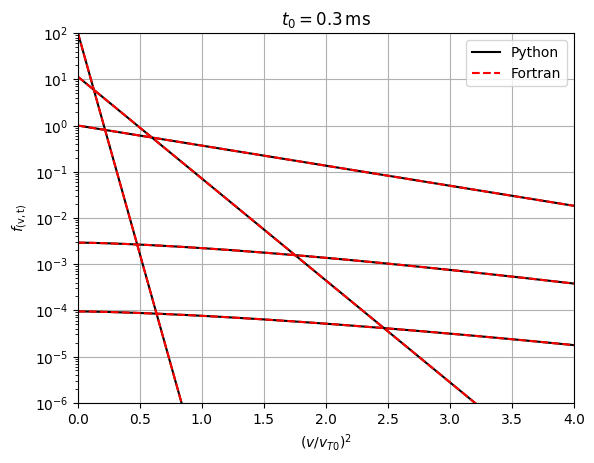

In [24]:
T0 = 3.1e3        # eV
Tf = 0.01*T0      # eV
t0 = 3e-4           # s
n0 = 2.8e19           # m^-3

tau = 0
vT0 = getvT0(T0)
print("vT0:", vT0)
x = np.linspace(0, 4, 8000)      # x = (v / vT0)^2
v = np.sqrt(x)*vT0

fm = getfm(v, n0, vT0)
norm_fac = max(fm)

plt.plot(x, fm/norm_fac, "k", label="Python")
plt.xlabel(r"$(v / v_{T0})^2$")
plt.yscale("log")
plt.ylim((1e-6, 1e2))
plt.xlim((0,4))
plt.ylabel(r"$f_{\mathrm{(v,t)}}$")
plt.title(r"$t_0 = 0.3\,\mathrm{ms}$")

plt.grid(True)

t = 5e-4
T = temperature(t, T0, Tf, t0)
vT = getvT0(T)
fm = getfm(v, n0, vT)
plt.plot(x, fm/norm_fac, "k")

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
plt.plot(x, f/norm_fac, "k")

t = 1e-3
T = temperature(t, T0, Tf, t0)
vT = getvT0(T)
fm = getfm(v, n0, vT)
plt.plot(x, fm/norm_fac, "k")

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
plt.plot(x, f/norm_fac, "k")


# from fortran
data = np.genfromtxt("figure_4a.csv", delimiter=",", skip_header=1)

x,fm0,fm1,f1,fm2,f2 = data.T

plt.plot(x,fm0, "r--", label="Fortran")
plt.plot(x,fm1,"r--")
plt.plot(x,f1,"r--")
plt.plot(x,fm2,"r--")
plt.plot(x,f2,"r--")

plt.legend()


vT0: 33022241.068624627


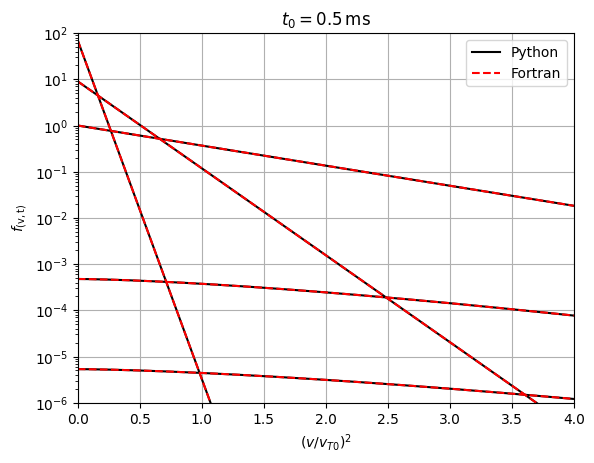

In [25]:
T0 = 3.1e3        # eV
Tf = 0.01*T0      # eV
t0 = 5e-4           # s
n0 = 2.8e19           # m^-3

tau = 0
vT0 = getvT0(T0)
print("vT0:", vT0)
x = np.linspace(0, 4, 8000)      # x = (v / vT0)^2
v = np.sqrt(x)*vT0

fm = getfm(v, n0, vT0)
norm_fac = max(fm)

#plt.plot(x, fm/norm_fac, "k", label=rf"$t = {tau*1e3:.1f}\,\mathrm{{ms}}$")
plt.plot(x, fm/norm_fac, "k", label="Python")
plt.xlabel(r"$(v / v_{T0})^2$")
plt.yscale("log")
plt.ylim((1e-6, 1e2))
plt.xlim((0,4))
plt.ylabel(r"$f_{\mathrm{(v,t)}}$")
plt.title(r"$t_0 = 0.5\,\mathrm{ms}$")

plt.grid(True)

t = 7.5e-4
T = temperature(t, T0, Tf, t0)
vT = getvT0(T)
fm = getfm(v, n0, vT)
plt.plot(x, fm/norm_fac, "k")

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
plt.plot(x, f/norm_fac, "k")

t = 1.5e-3
T = temperature(t, T0, Tf, t0)
vT = getvT0(T)
fm = getfm(v, n0, vT)
plt.plot(x, fm/norm_fac, "k")

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
plt.plot(x, f/norm_fac, "k")


# from fortran
data = np.genfromtxt("figure_4b.csv", delimiter=",", skip_header=1)

x,fm0,fm1,f1,fm2,f2 = data.T

plt.plot(x,fm0,"r--", label = "Fortran")

plt.plot(x,fm1,"r--")
plt.plot(x,f1,"r--")

plt.plot(x,fm2,"r--")
plt.plot(x,f2,"r--")

plt.legend()


vc= 387113724.76848686
vc= 350188466.13873345
vc= 316843461.1698636
vc= 286733535.279607
vc= 259546849.1063015
vc= 235001679.25021183
vc= 212843509.59779733
vc= 192842403.20791876
vc= 174790627.6338022
vc= 158500509.17014796
vc= 143802493.87833962
vc= 130543395.37896985
vc= 118584811.33228672
vc= 107801692.27408138
vc= 98081048.05552778
vc= 89320778.56744757
vc= 81428616.72775841
vc= 74321172.88937914
vc= 67923070.89711566
vc= 62166166.99710576
vc= 56988843.69084729
vc= 52335371.43564044
vc= 48155331.83067553
vc= 44403096.59736739
vc= 41037357.26638238
vc= 38020701.022902034
vc= 35319228.635475814
vc= 32902210.8011863
vc= 30741779.580075875
vc= 28812651.86585431
vc= 27091882.051809557
vc= 25558641.208553936
vc= 24194020.20607915
vc= 22980854.302661914
vc= 21903566.805716783
vc= 20948029.50271448
vc= 20101437.67866023
vc= 19352197.68966004
vc= 18689825.251974646
vc= 18104852.82759358
vc= 17588744.729711592
vc= 17133818.8199171
vc= 16733173.90800293
vc= 16380622.181525681
vc= 16070626.17

C:\Users\grace\AppData\Local\Temp\ipykernel_45812\1628749490.py:99: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m


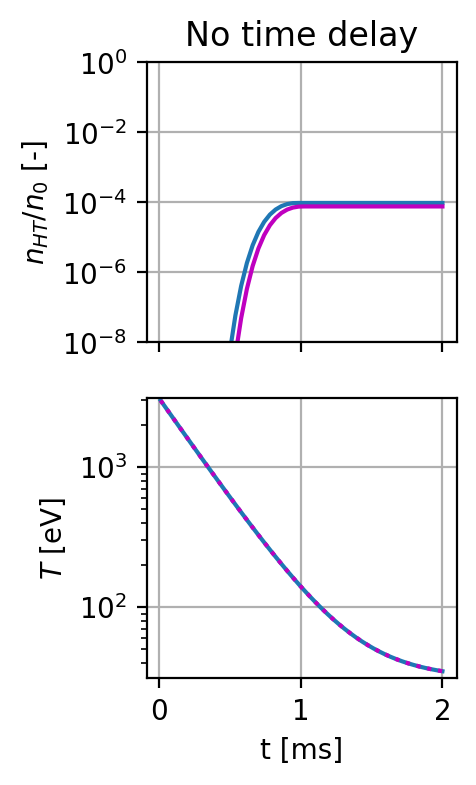

In [ ]:
# Generate Fig. 5
"""
The electrons in the runaway region v vc are caught by the electric field and become runaways,
so Eq. 19 should like in Eq. 4 only be used as long as it gives a positive runaway rate dnht / dt >0.
"""

# Constants
T0 = 3.1e3    # eV
Tf = 0.01*T0 # eV
t0 = 3e-4    # s
n0 = 2.8e19 # m^-3
E0 = 0.01 # V/m

t = np.linspace(1e-5,2e-3,50)
nht = np.zeros_like(t)

for ii in range(1,t.shape[0]):
    T = temperature(t[ii], T0, Tf, t0) # eV
    nht[ii] = getHT(n0,T0,E0,T,t[ii],t0)
    if (nht[ii] < nht[ii-1]):
        nht[ii] = nht[ii-1]



fig, axs = plt.subplots(2,1,sharex=True,figsize=(2,4),dpi=200)
axs[0].set_title("No time delay")
axs[0].plot(t*1e3,nht/n0)
print(nht/n0)
axs[0].set_ylabel('$n_{HT}/n_0$ [-]')
axs[0].set_yscale('log')
axs[0].set_ylim([1e-8,1e0])
axs[0].grid()

axs[1].plot(t*1e3,temperature(t, T0, Tf, t0))
axs[1].set_yscale('log')
axs[1].set_ylabel('$T$ [eV]')
axs[1].set_ylim([Tf,T0])
axs[1].grid()
axs[-1].set_xlabel('t [ms]')
    
# from fortran

data = np.genfromtxt("figure_5.csv", delimiter=",", skip_header=1)

t = data[:,0]
nht = data[:,1]
T = data[:,2]

print(nht)
axs[0].plot(t,nht, "m")
axs[1].plot(t,T, "m:")


[0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 1.88157879e+00
 2.87173434e+03 1.09458236e+06 1.33579931e+08 6.38591939e+09
 1.41129813e+11 1.65296714e+12 1.14922375e+13 5.21371276e+13
 1.67084908e+14 4.04235389e+14 7.80360160e+14 1.25830227e+15
 1.75918215e+15 2.19750489e+15 2.51214726e+15 2.67838343e+15
 2.70312110e+15 2.70312110e+15 2.70312110e+15 2.70312110e+15
 2.70312110e+15 2.70312110e+15 2.70312110e+15 2.70312110e+15
 2.70312110e+15 2.70312110e+15 2.70312110e+15 2.70312110e+15
 2.70312110e+15 2.70312110e+15 2.70312110e+15 2.70312110e+15
 2.70312110e+15 2.70312110e+15 2.70312110e+15 2.70312110e+15
 2.70312110e+15 2.70312110e+15 2.70312110e+15 2.70312110e+15
 2.70312110e+15 2.70312110e+15]
[0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 6.71992386e-20
 1.02561936e-16 3.90922255e-14 4.77071165e-12 2.28068543e-10
 5.04035033e-09 5.90345394e-08 4.10437044e-07 1.86204

C:\Users\grace\AppData\Local\Temp\ipykernel_47332\3781888552.py:102: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m


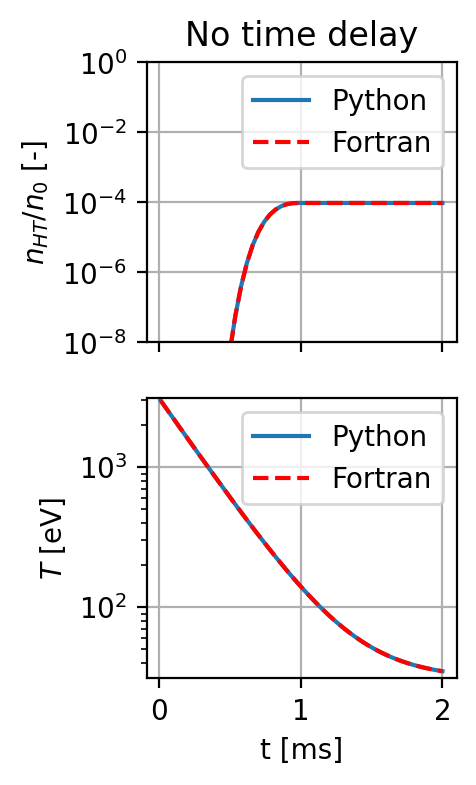

In [26]:
# Generate Fig. 5
"""
The electrons in the runaway region v vc are caught by the electric field and become runaways,
so Eq. 19 should like in Eq. 4 only be used as long as it gives a positive runaway rate dnht / dt >0.
"""

# Constants
T0 = 3.1e3    # eV
Tf = 0.01*T0 # eV
t0 = 3e-4    # s
n0 = 2.8e19 # m^-3
E0 = 0.01 # V/m

t = np.linspace(1e-5,2e-3,50)
nht = np.zeros_like(t)

for ii in range(1,t.shape[0]):
    T = temperature(t[ii], T0, Tf, t0) # eV
    nht[ii] = getHT(n0,T0,E0,T,t[ii],t0)
    if (nht[ii] < nht[ii-1]):
        nht[ii] = nht[ii-1]



fig, axs = plt.subplots(2,1,sharex=True,figsize=(2,4),dpi=200)
axs[0].set_title("No time delay")
axs[0].plot(t*1e3,nht/n0, label = "Python")
print(nht)
axs[0].set_ylabel('$n_{HT}/n_0$ [-]')
axs[0].set_yscale('log')
axs[0].set_ylim([1e-8,1e0])
axs[0].grid()

axs[1].plot(t*1e3,temperature(t, T0, Tf, t0), label = "Python")
axs[1].set_yscale('log')
axs[1].set_ylabel('$T$ [eV]')
axs[1].set_ylim([Tf,T0])
axs[1].grid()
axs[-1].set_xlabel('t [ms]')

    
# from fortran

data = np.genfromtxt("figure_5.csv", delimiter=",", skip_header=1)

t = data[:,0]
nht = data[:,1]
T = data[:,2]

print(nht)
axs[0].plot(t,nht, "r--", label = "Fortran")
axs[1].plot(t,T, "r--", label = "Fortran")

axs[0].legend()
axs[1].legend()

E0:  0.006921988661295184
[0.00000000e+00 0.00000000e+00 0.00000000e+00 5.16512243e-23
 5.65301224e-20 1.20092315e-17 1.29907870e-15 7.82304404e-14
 2.40197622e-12 4.49724470e-11 5.56474045e-10 4.77741336e-09
 2.97030142e-08 1.38914495e-07 5.05495869e-07 1.47529130e-06
 3.54892327e-06 7.21282407e-06 1.26650149e-05 1.96036413e-05
 2.72344482e-05 3.45053543e-05 4.04322990e-05 4.43542317e-05
 4.60319338e-05 4.60319338e-05 4.60319338e-05 4.60319338e-05
 4.60319338e-05 4.60319338e-05 4.60319338e-05 4.60319338e-05
 4.60319338e-05 4.60319338e-05 4.60319338e-05 4.60319338e-05
 4.60319338e-05 4.60319338e-05 4.60319338e-05 4.60319338e-05
 4.60319338e-05 4.60319338e-05 4.60319338e-05 4.60319338e-05
 4.60319338e-05 4.60319338e-05 4.60319338e-05 4.60319338e-05
 4.60319338e-05 4.60319338e-05]


C:\Users\grace\AppData\Local\Temp\ipykernel_6312\2726464352.py:105: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m


[2.48849140e-08 4.03767512e-08 6.87517195e-08 9.04600350e-08
 1.48449394e-07 2.53639202e-07 3.30496521e-07 5.48548487e-07
 9.17376163e-07 1.23517910e-06 1.99404810e-06 3.29717204e-06
 4.38932401e-06 6.99728400e-06 1.13288638e-05 1.50886685e-05
 2.34057630e-05 3.71951406e-05 4.88822410e-05 7.40681055e-05
 1.10560409e-04 1.34226977e-04 1.80336618e-04 2.29921525e-04
 2.52166800e-04 2.82101263e-04 2.94824417e-04 2.94824417e-04
 2.94824417e-04 2.94824417e-04 2.94824417e-04 2.94824417e-04
 2.94824417e-04 2.94824417e-04 2.94824417e-04 2.94824417e-04
 2.94824417e-04 2.94824417e-04 2.94824417e-04 2.94824417e-04
 2.94824417e-04 2.94824417e-04 2.94824417e-04 2.94824417e-04]


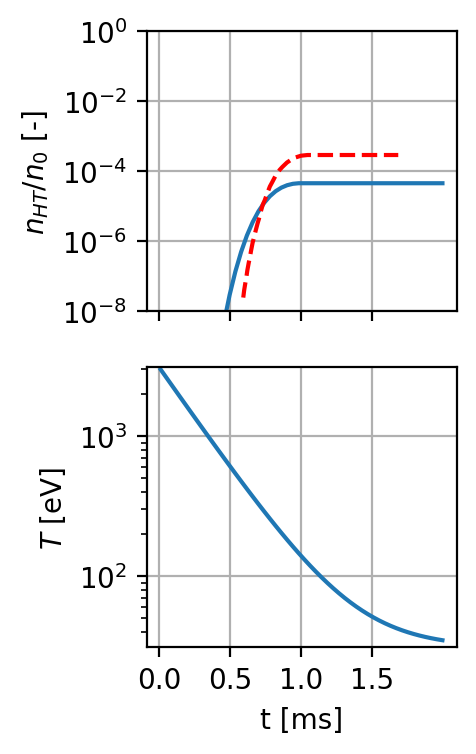

In [8]:
# Generate Fig. 5
"""
The electrons in the runaway region v vc are caught by the electric field and become runaways,
so Eq. 19 should like in Eq. 4 only be used as long as it gives a positive runaway rate dnht / dt >0.
"""

# Constants
T0 = 3.1e3    # eV
Tf = 0.01*T0 # eV
t0 = 3e-4    # s
n0 = 2.8e19 # m^-3
E0 = 0.01 # V/m

E0 = RE.getDreicerField(n0,15,T0)/510
print("E0: ", E0)

t = np.linspace(1e-5,2e-3,50)
nht = np.zeros_like(t)

for ii in range(1,t.shape[0]):
    T = temperature(t[ii], T0, Tf, t0) # eV
    nht[ii] = getHT(n0,T0,E0,T,t[ii],t0)
    if (nht[ii] < nht[ii-1]):
        nht[ii] = nht[ii-1]



fig, axs = plt.subplots(2,1,sharex=True,figsize=(2,4),dpi=200)
#axs[0].set_title("No time delay")
axs[0].plot(t*1e3,nht/n0, label = "Python")
print(nht/n0)
axs[0].set_ylabel('$n_{HT}/n_0$ [-]')
axs[0].set_yscale('log')
axs[0].set_ylim([1e-8,1e0])
axs[0].grid()

axs[1].plot(t*1e3,temperature(t, T0, Tf, t0), label = "Python")
axs[1].set_yscale('log')
axs[1].set_ylabel('$T$ [eV]')
axs[1].set_ylim([Tf,T0])
axs[1].grid()
axs[-1].set_xlabel('t [ms]')

    
# from fortran

data = np.genfromtxt("Default Dataset.csv", delimiter=",", skip_header=1)

t = data[:,0]
nht = data[:,1]
#T = data[:,2]

print(nht)
axs[0].plot(t,nht, "r--", label = "Fortran")
#axs[1].plot(t,T, "r--", label = "Fortran")
axs[0].set_xticks([0,0.5, 1, 1.5])

#axs[0].legend()
#axs[1].legend()

Iht = 147 kA


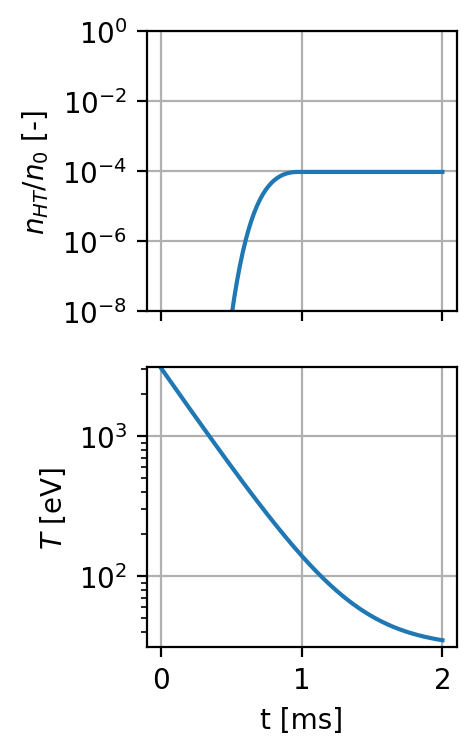

In [46]:
# Generate Fig. 5

def temperature(t, T0, Tf, t0):
    """
    Parameters:
    t: Time (s)
    T0: initial temp (eV)
    Tfinal: final temp (eV)
    t0: initial time (s)
    """
    return Tf + (T0 - Tf) * np.exp(-t / t0)


# Constants
T0 = 3.1e3    # eV
Tf = 0.01*T0 # eV
t0 = 3e-4    # s
n0 = 2.8e19 # m^-3
E0 = 0.01 # V/m

t = np.linspace(0,2e-3,200)
nht = np.zeros_like(t)
nht_rate = np.zeros_like(t)

dt = np.diff(t)[0]

for ii in range(1,t.shape[0]):
    T = temperature(t[ii], T0, Tf, t0) # eV
    # Rate
    nht_rate[ii], nht[ii] = RE.get_HT_rate(ne=n0,
                                           T=T,
                                           t=t[ii],
                                           T0=T0,
                                           E0=E0,
                                           nht=nht[ii-1],
                                           dt=dt)

# Plot
fig, axs = plt.subplots(2,1,sharex=True,figsize=(2,4),dpi=200)
axs[0].plot(t*1e3,nht/n0,'-')
axs[0].set_ylabel('$n_{HT}/n_0$ [-]')
axs[0].set_yscale('log')
axs[0].set_ylim([1e-8,1e0])
axs[0].grid()

axs[1].plot(t*1e3,temperature(t, T0, Tf, t0))
axs[1].set_yscale('log')
axs[1].set_ylabel('$T$ [eV]')
axs[1].set_ylim([Tf,T0])
axs[1].grid()
axs[-1].set_xlabel('t [ms]')
    
    
# HT Current
Iht = nht[-1] * const.c * const.e * np.pi * 0.6**2
print('Iht = %1.3g kA'%(Iht/1e3))

tt = 1*t
NHT = 1*nht

## Troubleshooting, ignore below

In [47]:
nht_rate

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 4.90359790e+01, 1.21452773e+03,
       1.15801976e+04, 9.29569633e+04, 6.67575128e+05, 4.33280742e+06,
       2.55494711e+07, 1.37505071e+08, 6.78329268e+08, 3.07974620e+09,
       1.29188334e+10, 5.02533941e+10, 1.81913359e+11, 6.14850737e+11,
       1.94652541e+12, 5.78961008e+12, 1.62251124e+13, 4.29602062e+13,
       1.07750500e+14, 2.56641524e+14, 5.81861795e+14, 1.25857229e+15,
       2.60278911e+15, 5.15696124e+15, 9.80832668e+15, 1.79413015e+16,
       3.16189294e+16, 5.37793400e+16, 8.84231441e+16, 1.40758537e+17,
      

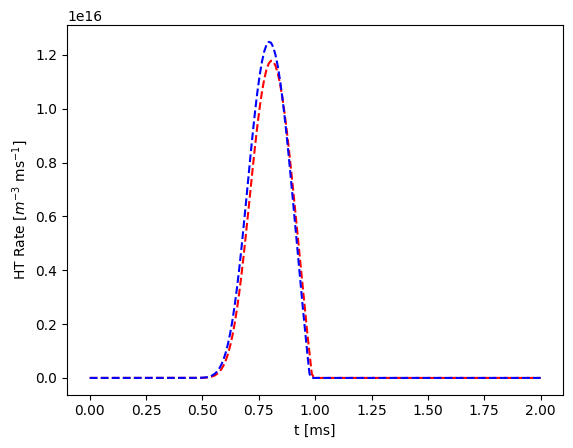

In [48]:


data = np.loadtxt("HT_rate_scan.csv",delimiter=",",skiprows=1)

t = data[:,0]
rate = data[:,1]

plt.plot(t,rate,'r--')
plt.xlabel("t [ms]")
plt.ylabel("HT Rate [$m^{-3}$ ms$^{-1}$]")


#rate = np.gradient(nht,t)

#plt.plot(t*1e3,rate / 1e3, 'g--')
plt.plot(t,nht_rate / 1e3,'b--')

In [60]:
T0 = 3.1e3    # eV
Tf = 0.01*T0 # eV
t0 = 3e-4    # s
n0 = 2.8e19 # m^-3
E0 = 0.01 # V/m

t = np.linspace(0,2e-3,200)

get_vc(T0, E0, n0)

1st half: 545234202597179.44
2nd half 353.02142172605437
4.966747565399999e-16


np.float64(438724689.72526246)

D field   3.5302142220450108     
 first half:   545234203339370.56     
 2nd half:   353.02142220450105
 temp times e   4.9667475653999994E-016
 e=    1.6021766339999999E-019
 vc =    438724690.32116568       m/s
 Columb Log =    3.5302142220450108

In [58]:
RE.getDreicerField(n0,15,T0)

3.5302142172605437